# ML Weather Predictor: Analysis Notebook

**Goal.** Predict tomorrow's maximum temperature for Bengaluru, Delhi and Mumbai from recent daily weather.

**Forecast definition.** Let *D* be the last fully completed day (yesterday, in Indian time). The target is the
maximum temperature on *D + 2* days, which is tomorrow when the model is run today. Today's partial day is never used.

**What this notebook does.** It loads the saved data and trained models, checks the data, explains the EDA,
shows how features are built, and re-evaluates the saved models on the untouched 2023 test year.
Every number below is computed when the notebook runs; nothing is retrained.

Run from the `notebooks/` folder with the packages in `requirements-dev.txt` installed.

In [1]:
import os, sys, json
PROJECT_ROOT = os.path.abspath("..")
sys.path.insert(0, PROJECT_ROOT)

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.data_fetch import CITIES as CITY_COORDS, DAILY_VARIABLES, START_DATE, END_DATE
from src.features import make_features, compute_climatology_map, FEATURE_COLUMNS, FORECAST_HORIZON_DAYS, REQUIRED_HISTORY_DAYS
from src.eda import assign_season, climatology_anomaly, partial_autocorrelation
from src.evaluate import evaluate_city, load_split
from src.train import TEST_START_DATE

pd.set_option("display.precision", 3)
CITIES = ["bengaluru", "delhi", "mumbai"]
FIG = lambda name: Image(filename=os.path.join(PROJECT_ROOT, "figures", name))
data = {c: pd.read_csv(os.path.join(PROJECT_ROOT, "data", f"{c}.csv"), parse_dates=["date"]) for c in CITIES}
with open(os.path.join(PROJECT_ROOT, "models", "metrics.json")) as f:
    saved_metrics = json.load(f)

## 1. Data source and validation

Data comes from the free Open-Meteo Historical Weather API (`src/data_fetch.py`), one CSV per city, with
four daily variables: maximum 2 m temperature (°C), mean relative humidity (%), maximum 10 m wind speed (km/h)
and total precipitation (mm). Dates are local Indian dates (`timezone=Asia/Kolkata`).

In [2]:
print("Requested period:", START_DATE, "to", END_DATE)
print("Coordinates:", CITY_COORDS)
checks = []
for c, df in data.items():
    full_range = pd.date_range(df["date"].min(), df["date"].max(), freq="D")
    checks.append({
        "city": c, "rows": len(df), "first": df["date"].min().date(), "last": df["date"].max().date(),
        "missing_dates": len(full_range.difference(df["date"])),
        "duplicate_dates": int(df["date"].duplicated().sum()),
        "missing_values": int(df[DAILY_VARIABLES].isna().sum().sum()),
    })
pd.DataFrame(checks).set_index("city")

Requested period: 2019-01-01 to 2023-12-31
Coordinates: {'Bengaluru': {'latitude': 12.9716, 'longitude': 77.5946}, 'Delhi': {'latitude': 28.6139, 'longitude': 77.209}, 'Mumbai': {'latitude': 19.076, 'longitude': 72.8777}}


,rows,first,last,missing_dates,duplicate_dates,missing_values
city,,,,,,
bengaluru,1826,2019-01-01,2023-12-31,0,0,0
delhi,1826,2019-01-01,2023-12-31,0,0,0
mumbai,1826,2019-01-01,2023-12-31,0,0,0


**Result.** Each city has 1826 consecutive days with no missing dates, no duplicate dates and no missing values,
so no imputation was needed. (`src/eda.py` would interpolate gaps in time if any existed; none do.)
The feature function additionally refuses data with gaps, because lag features are row shifts and a gap would
silently misalign them.

## 2. Summary statistics

In [3]:
pd.concat({c: df[DAILY_VARIABLES].describe().T[["mean", "std", "min", "50%", "max"]] for c, df in data.items()})

mean     std   min   50%    max
bengaluru temperature_2m_max         28.769   2.902  18.5  28.2   37.1
          relative_humidity_2m_mean  70.751  14.674  26.0  75.0   96.0
          wind_speed_10m_max         17.977   5.060   5.6  17.3   42.6
          precipitation_sum           3.098   6.038   0.0   0.5   73.4
delhi     temperature_2m_max         30.197   6.969  12.9  31.5   45.4
          relative_humidity_2m_mean  62.998  18.375  14.0  66.0   96.0
          wind_speed_10m_max         15.663   5.063   5.5  14.8   36.1
          precipitation_sum           1.982   6.470   0.0   0.0  125.4
mumbai    temperature_2m_max         30.399   2.529  23.1  30.3   38.7
          relative_humidity_2m_mean  74.903  13.206  31.0  77.0   93.0
          wind_speed_10m_max         19.251   5.027   8.7  18.7   61.9
          precipitation_sum           6.768  17.197   0.0   0.0  200.7

Delhi has the largest spread of maximum temperature (from about 13 °C to 45 °C); coastal Mumbai has the smallest.
Precipitation is heavily skewed: most days have little or no rain and a few monsoon days have very large totals.

## 3. Exploratory figures
### 3.1 Distributions

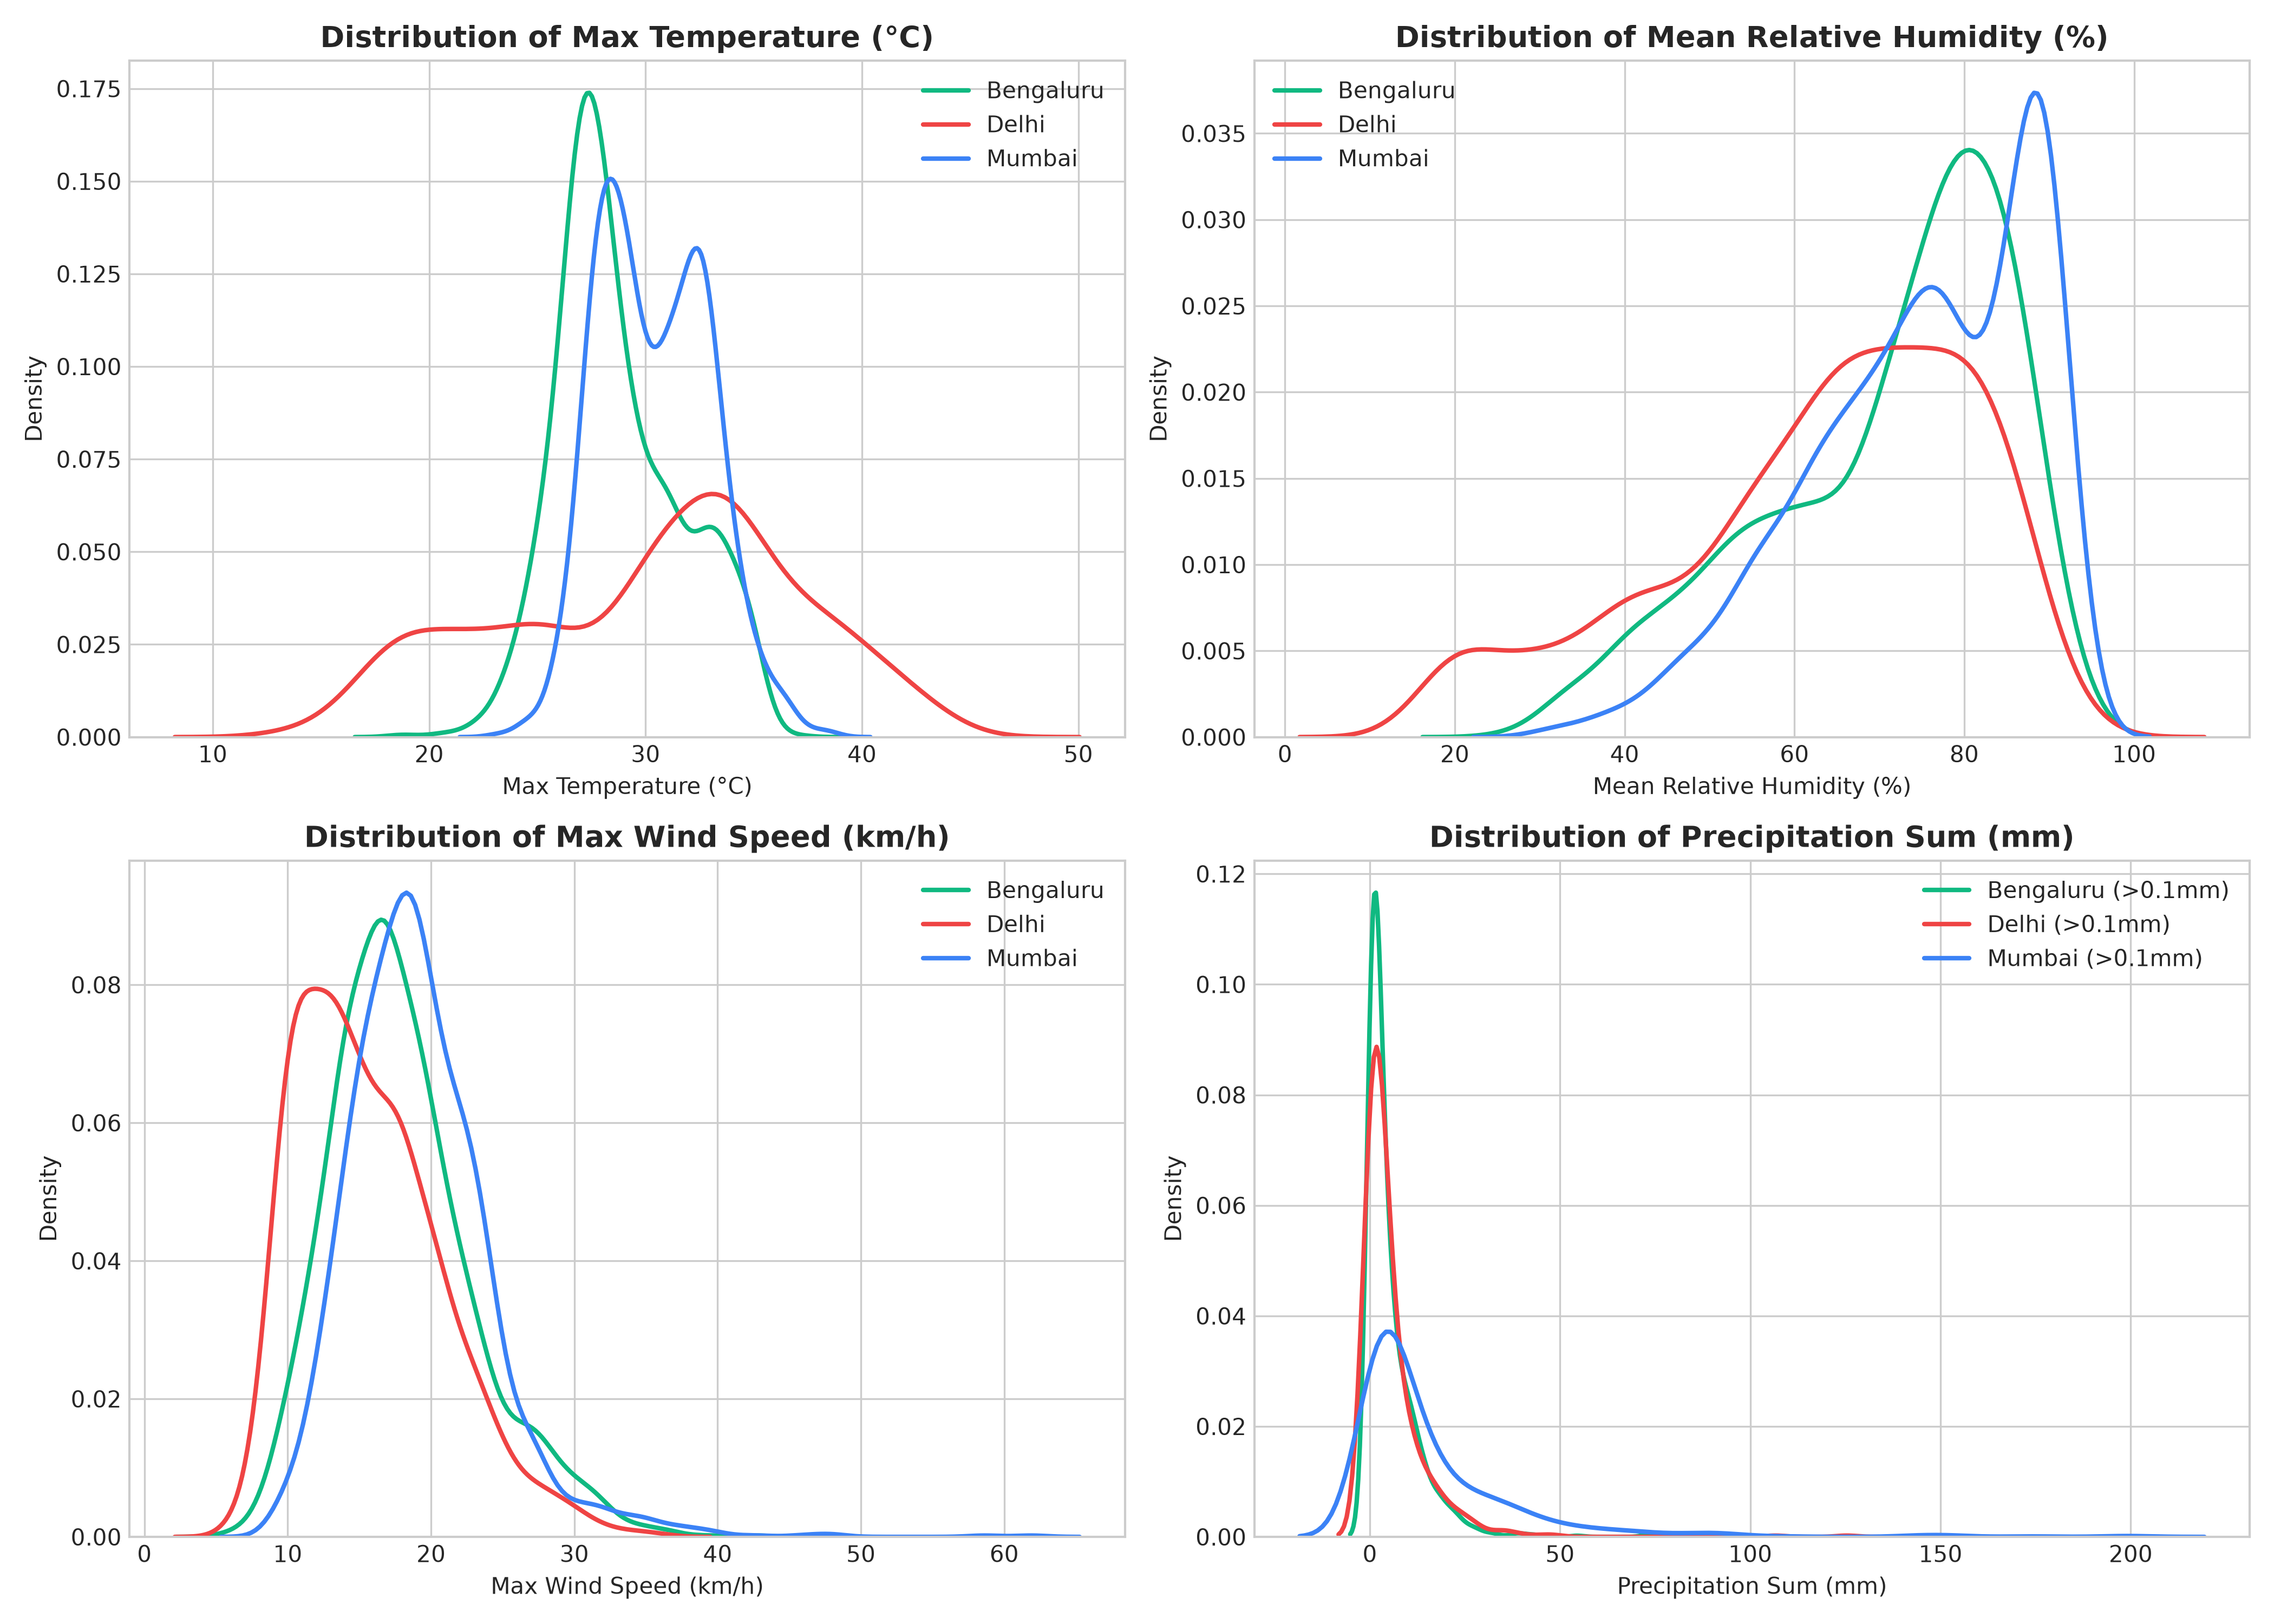

In [4]:
display(FIG("1_distributions.png"))

Delhi's temperature distribution is wide and has two humps (cool winters, very hot pre-monsoon months).
Mumbai's is narrow, consistent with the moderating effect of the sea. The rain panel only includes days with more than 0.1 mm.

### 3.2 Seasonal pattern (Indian Meteorological Department seasons)

,bengaluru,delhi,mumbai
season,,,
Winter,27.8,20.8,30.0
Pre-monsoon,32.5,34.3,32.6
Monsoon,27.7,34.6,28.5
Post-monsoon,26.8,29.0,31.4


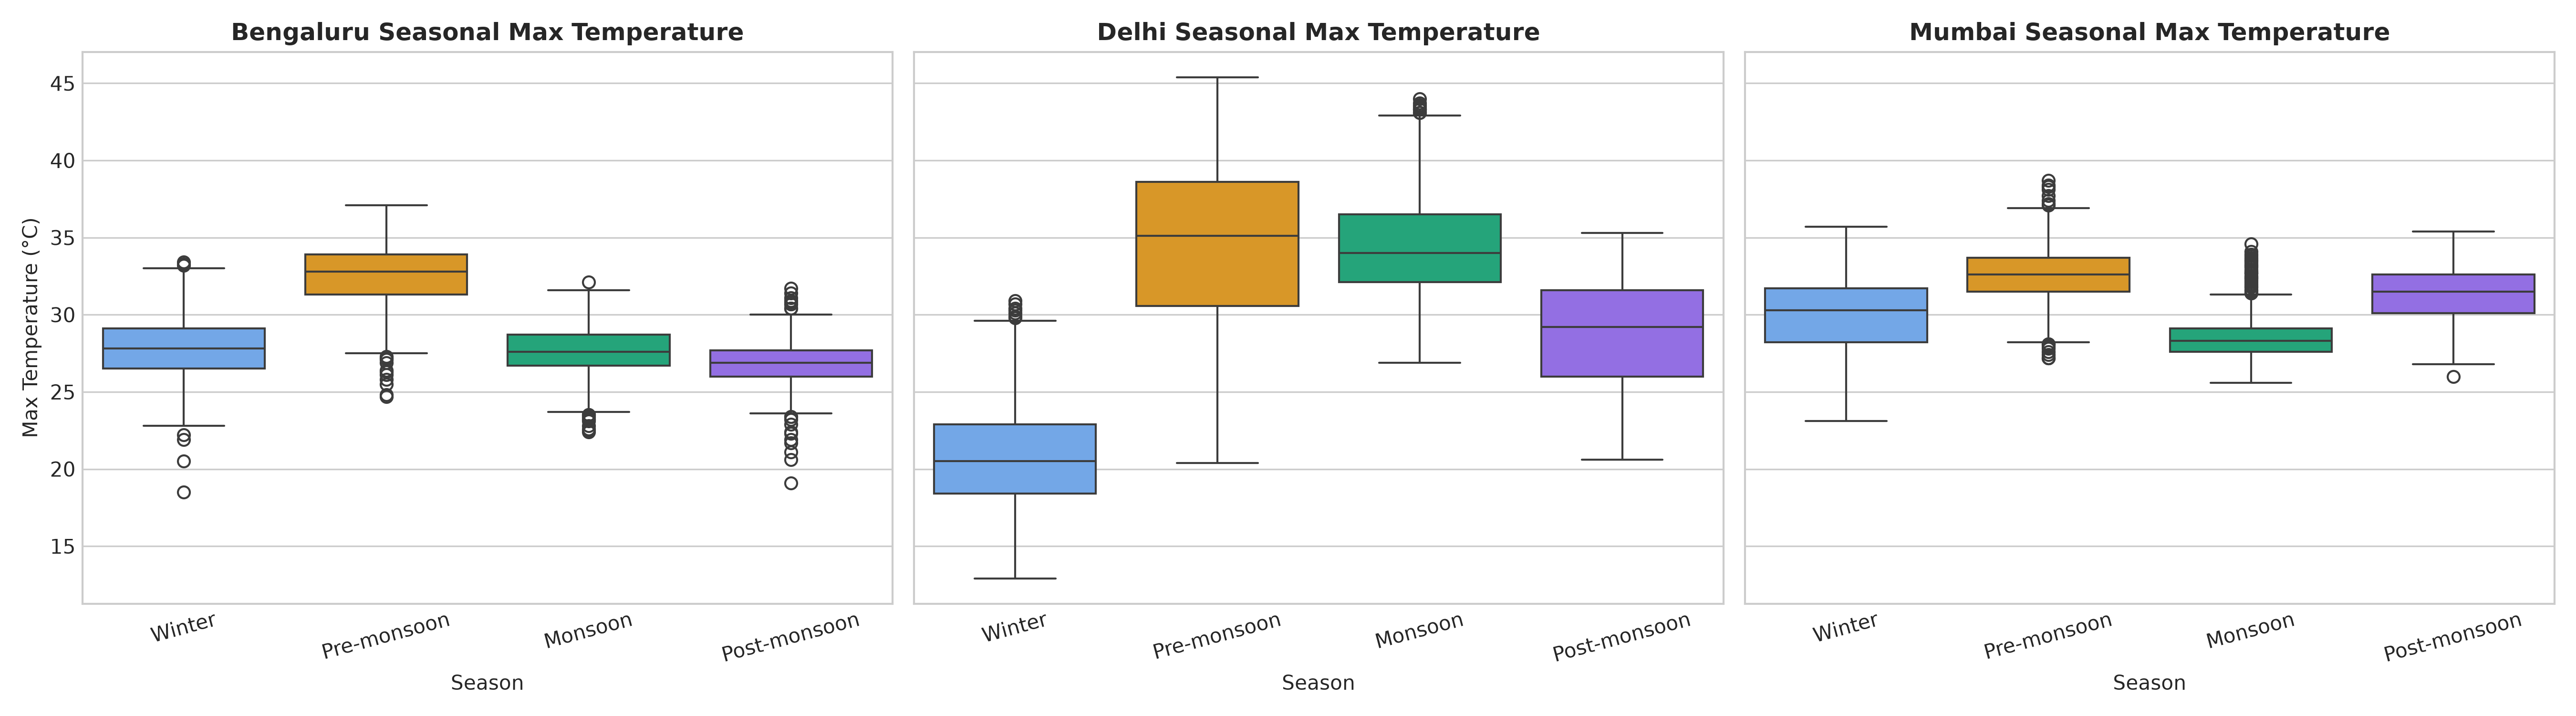

In [5]:
season_table = pd.concat({c: df.assign(season=df["date"].dt.month.map(assign_season))
                          .groupby("season")["temperature_2m_max"].mean()
                          for c, df in data.items()}, axis=1)
display(season_table.loc[["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"]].round(1))
display(FIG("2_seasonal_trends.png"))

Pre-monsoon (March–May) is the hottest season in all three cities. Monsoon rain and cloud lower the maximum
temperature, especially in Bengaluru and Mumbai. Delhi has the biggest difference between seasons.

### 3.3 Same-day correlations

,bengaluru,delhi,mumbai
relative_humidity_2m_mean,-0.77,-0.60,-0.62
wind_speed_10m_max,-0.23,0.35,-0.05
precipitation_sum,-0.32,-0.03,-0.41


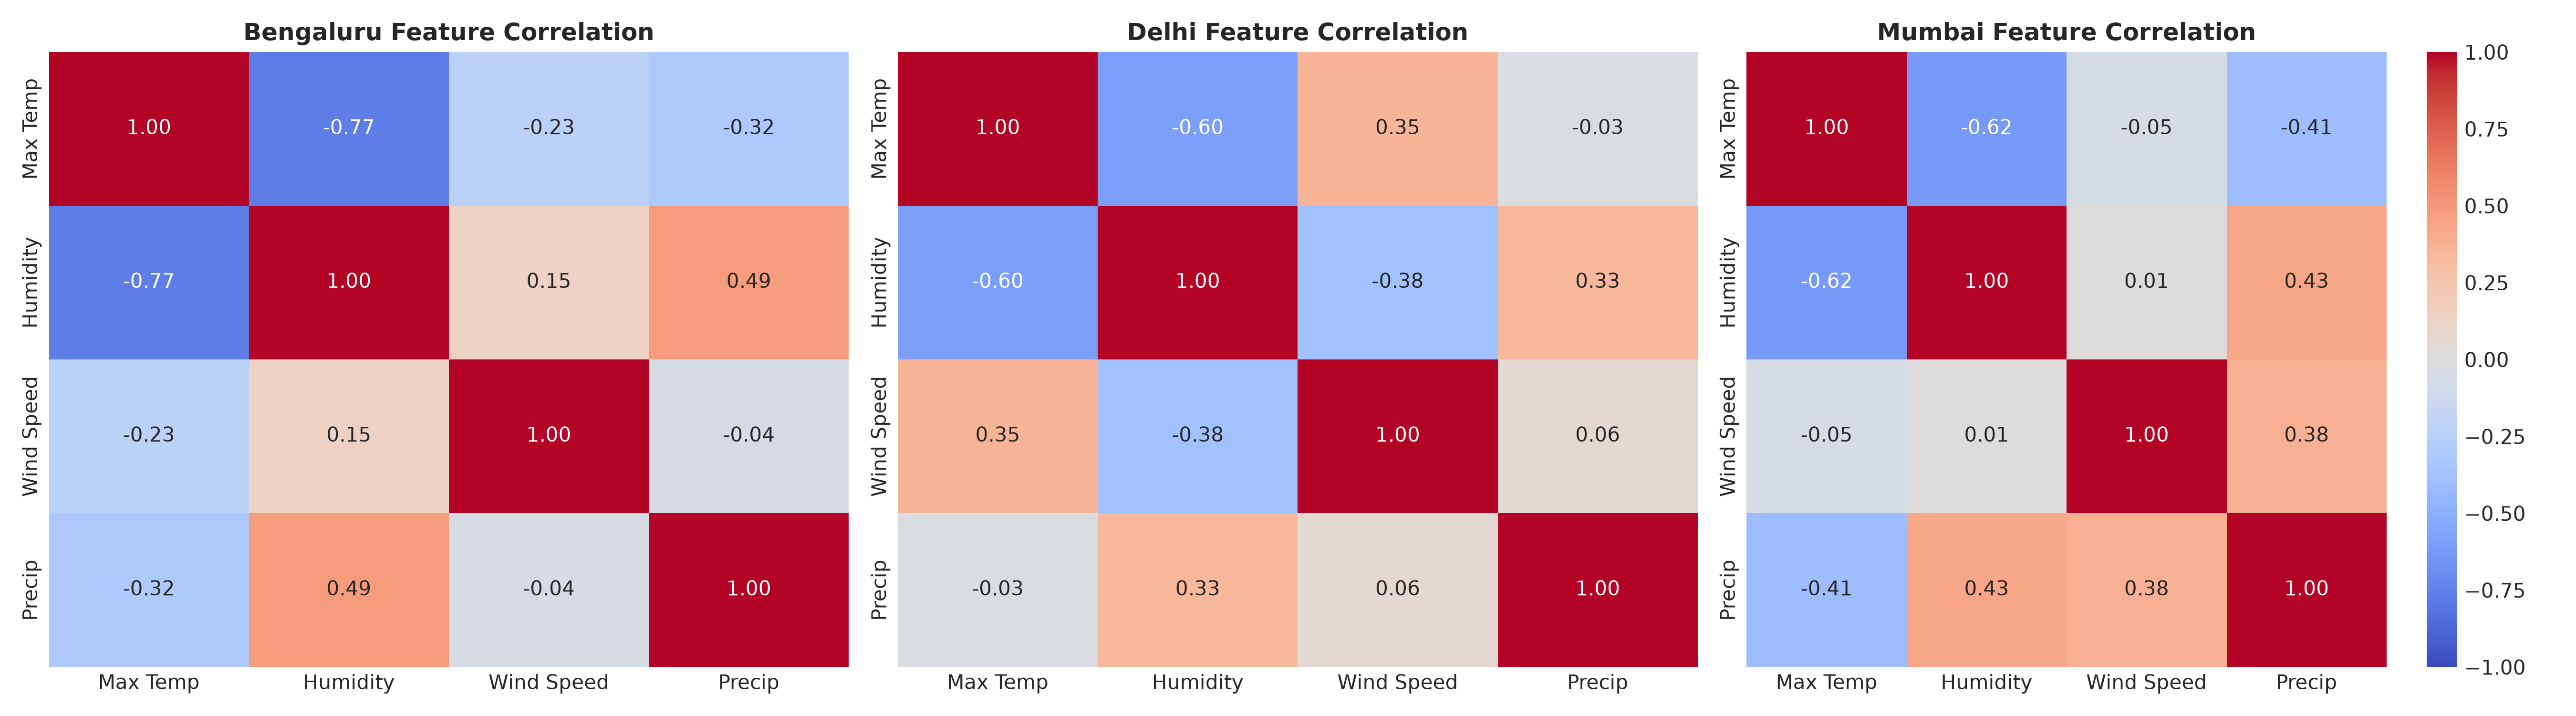

In [6]:
corr = pd.DataFrame({c: df[DAILY_VARIABLES[1:]].corrwith(df["temperature_2m_max"]) for c, df in data.items()})
display(corr.round(2))
display(FIG("3_correlation_heatmaps.png"))

*Interpretation (computed above).* Humidity is clearly negatively correlated with maximum temperature in all three
cities. Precipitation is negatively correlated in Bengaluru and Mumbai, but almost uncorrelated in Delhi, where the
hottest period (pre-monsoon) is dry and the rainy monsoon is still warm. Wind speed is only weakly correlated in
Bengaluru and Mumbai, and moderately positively correlated in Delhi (in Delhi both wind speed and temperature peak in April–June).

These are same-day Pearson correlations: they describe linear association, not cause and effect, and they do not
show how well a variable predicts the temperature two days later.

### 3.4 City comparison

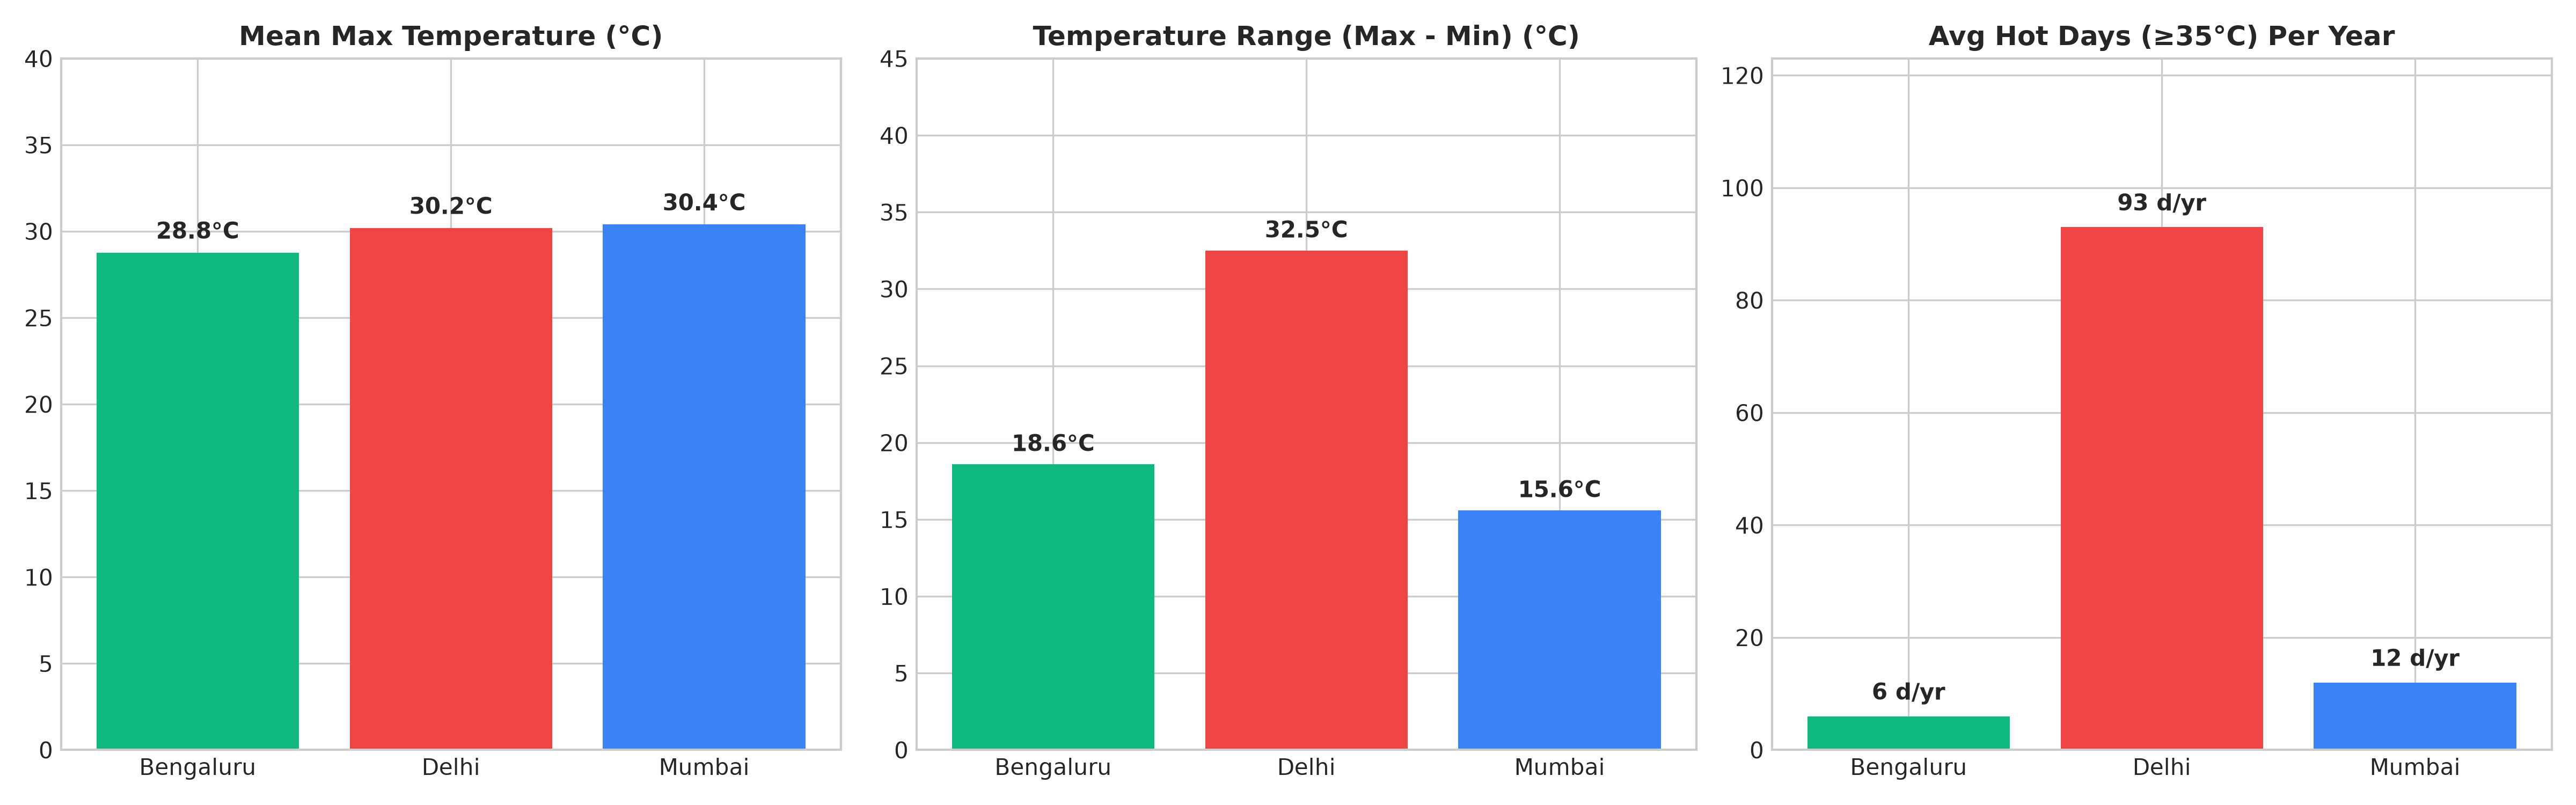

In [7]:
display(FIG("5_city_comparison.png"))

## 4. How long is the weather's memory? (choice of the 7-day lag window)

The raw autocorrelation of maximum temperature (figure 4) stays high for weeks. Most of that comes from the
seasonal cycle: a hot day in May is followed by more hot days simply because it is May. To see day-to-day memory we
remove the day-of-year average (the *anomaly*) and also look at the partial autocorrelation, which measures what
lag *k* adds once lags 1 to *k−1* are known.

,raw ACF lag1,raw ACF lag7,raw ACF lag30,anomaly ACF lag1,anomaly ACF lag7,anomaly ACF lag14,PACF lag1,max |PACF| lags 2-10
bengaluru,0.92,0.79,0.62,0.75,0.36,0.17,0.92,0.17
delhi,0.97,0.89,0.70,0.84,0.38,0.23,0.97,0.13
mumbai,0.89,0.62,0.34,0.79,0.24,0.17,0.89,0.10


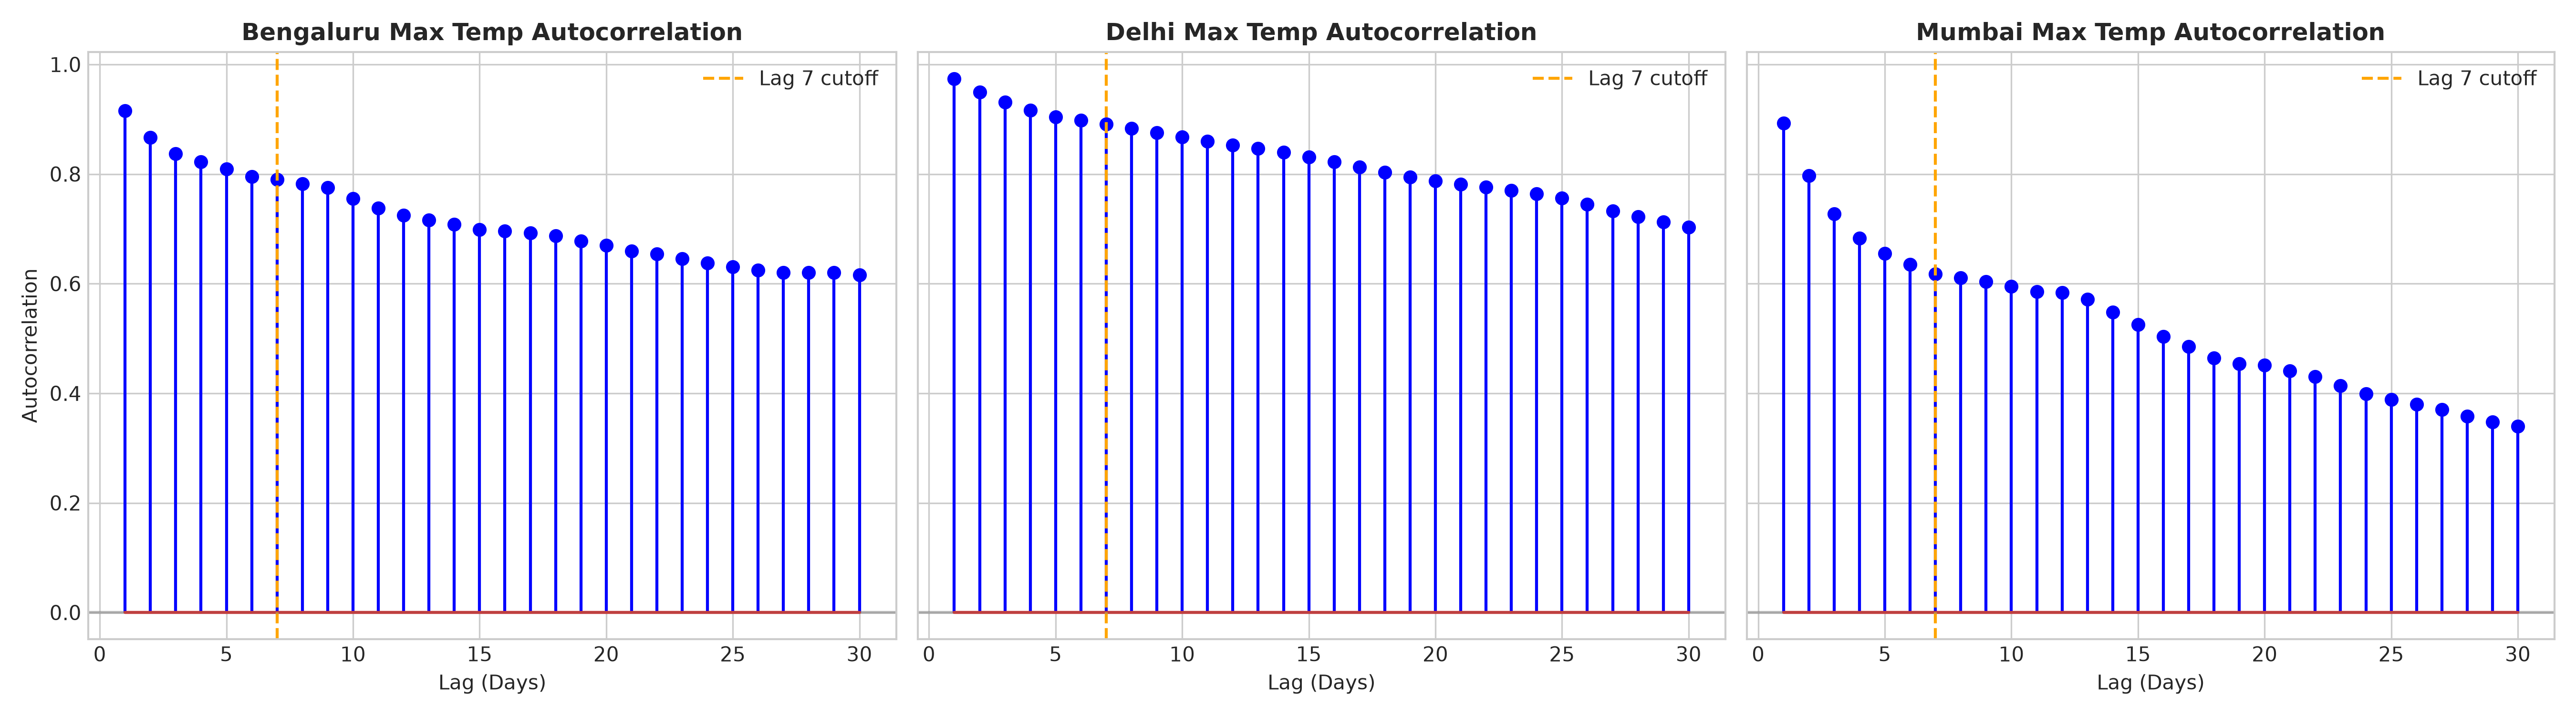

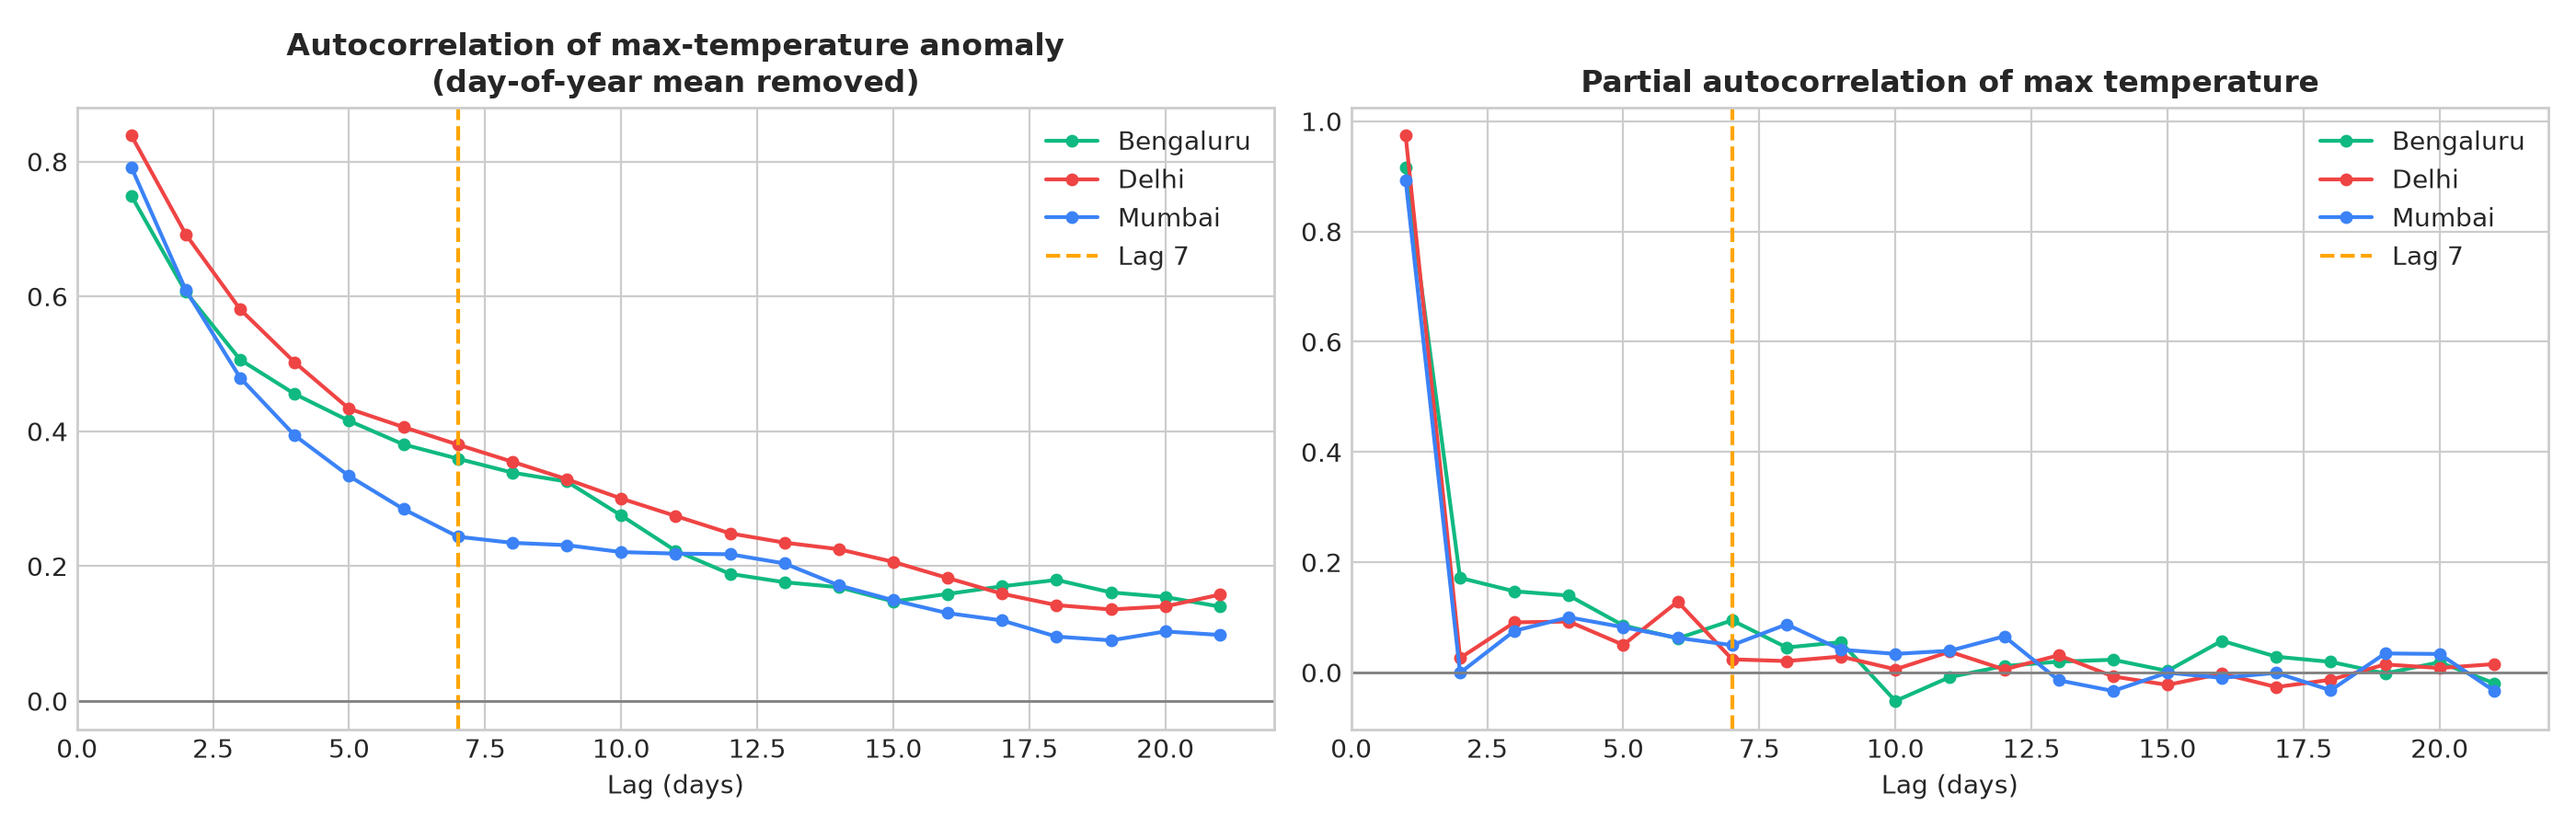

In [8]:
rows = {}
for c, df in data.items():
    s, anom = df["temperature_2m_max"], climatology_anomaly(df)
    pacf = partial_autocorrelation(s, 10)
    rows[c] = {"raw ACF lag1": s.autocorr(1), "raw ACF lag7": s.autocorr(7), "raw ACF lag30": s.autocorr(30),
               "anomaly ACF lag1": anom.autocorr(1), "anomaly ACF lag7": anom.autocorr(7), "anomaly ACF lag14": anom.autocorr(14),
               "PACF lag1": pacf[0], "max |PACF| lags 2-10": np.abs(pacf[1:]).max()}
display(pd.DataFrame(rows).T.round(2))
display(FIG("4_autocorrelation.png"))
display(FIG("6_memory_diagnostics.png"))

*Interpretation.* The raw autocorrelation is still high at lag 30, so on its own it cannot choose a window.
After removing the seasonal cycle, the autocorrelation falls from roughly 0.75–0.84 at lag 1 to about 0.24–0.38 at lag 7.
The partial autocorrelation is dominated by lag 1, with only small values at later lags. So most predictive information
is in the last few days, and a 7-day window is a reasonable, not uniquely optimal, choice.

## 5. Feature engineering (`src/features.py`)

One function, `make_features`, is used both in training and by the live API, so the model always sees inputs built
the same way. For a row dated *D* it uses only days up to *D*:

* max temperature on D, D−1, …, D−6 (7 lags), 7-day mean and standard deviation;
* change from D−1 to D and the change in that change (these two are exact linear combinations of the lags);
* mean humidity on D and D−1, an approximate dew point (max temperature − (100 − humidity)/5, a rough moisture index);
* max wind speed on D; rain on D, D−1 and the 3-day total;
* sine/cosine of the target date's day-of-year (annual cycle) and a second harmonic.

The target is the maximum temperature on D + 2. The two baselines are persistence (the max temperature on D) and
climatology (the training-years average for the target date's day-of-year).

In [9]:
df = data["delhi"]
clim = compute_climatology_map(df[df["date"] < TEST_START_DATE])
feats = make_features(df, climatology_map=clim, is_training=True)
print(len(FEATURE_COLUMNS), "features; horizon =", FORECAST_HORIZON_DAYS, "days; history needed =", REQUIRED_HISTORY_DAYS, "days")
feats[["date", "target_date", "temp_lag_0", "temp_lag_1", "temp_roll_mean_7", "baseline_persistence",
       "baseline_climatology", "target_temp_d2"]].iloc[100:105]

22 features; horizon = 2 days; history needed = 7 days


,date,target_date,temp_lag_0,temp_lag_1,temp_roll_mean_7,baseline_persistence,baseline_climatology,target_temp_d2
100,2019-04-17,2019-04-19,25.9,31.1,35.029,25.9,36.075,29.9
101,2019-04-18,2019-04-20,27.9,25.9,33.600,27.9,35.350,32.8
102,2019-04-19,2019-04-21,29.9,27.9,32.543,29.9,34.500,35.4
103,2019-04-20,2019-04-22,32.8,29.9,31.971,32.8,35.200,37.3
104,2019-04-21,2019-04-23,35.4,32.8,31.657,35.4,36.675,39.1


**No-leakage check.** If a feature used any future value, removing the rows after date *t* would change the
features for *t*. The check below (also an automated test in `tests/test_features.py`) shows they are identical.

In [10]:
t = 1000
full = make_features(df, climatology_map=clim, is_training=False)
truncated = make_features(df.iloc[:t + 1], climatology_map=clim, is_training=False)
d = df["date"].iloc[t]
same = np.allclose(full.loc[full["date"] == d, FEATURE_COLUMNS].values, truncated.loc[truncated["date"] == d, FEATURE_COLUMNS].values)
print(f"Features for {d.date()} unchanged after removing all later data: {same}")
X = load_split("delhi")[0][FEATURE_COLUMNS].values
print("Rank of the training feature matrix:", np.linalg.matrix_rank(X), "of", X.shape[1], "columns")

Features for 2021-09-27 unchanged after removing all later data: True
Rank of the training feature matrix: 19 of 22 columns


The feature matrix has rank 19, not 22: the daily change, its acceleration and the approximate dew point are exact
linear combinations of other columns. Trees are unaffected; for a linear model it means plain least squares has no
unique solution, which is one reason the project uses Ridge regression (an L2 penalty) as its linear model.

## 6. Chronological split and validation

Rows are split by **target date**: targets before 2023-01-01 are training data, targets in 2023 form the final test
year. Hyperparameters, ensemble weights and the interval offsets were all chosen with a 5-fold `TimeSeriesSplit`
inside the training years (each fold trains on the past and validates on the following block). The test year was
used only once, for the final evaluation below. A random split would let the model train on days surrounding each
test day and give over-optimistic errors.

In [11]:
from sklearn.model_selection import TimeSeriesSplit
train, test = load_split("delhi")
print(f"Training rows: {len(train)} (targets {train['target_date'].min().date()} to {train['target_date'].max().date()})")
print(f"Test rows:     {len(test)} (targets {test['target_date'].min().date()} to {test['target_date'].max().date()})")
for i, (tr, va) in enumerate(TimeSeriesSplit(n_splits=5).split(train), 1):
    print(f"Fold {i}: train {len(tr):4d} rows up to {train['target_date'].iloc[tr[-1]].date()}, "
          f"validate {train['target_date'].iloc[va[0]].date()} to {train['target_date'].iloc[va[-1]].date()}")

Training rows: 1453 (targets 2019-01-09 to 2022-12-31)
Test rows:     365 (targets 2023-01-01 to 2023-12-31)
Fold 1: train  243 rows up to 2019-09-08, validate 2019-09-09 to 2020-05-07
Fold 2: train  485 rows up to 2020-05-07, validate 2020-05-08 to 2021-01-04
Fold 3: train  727 rows up to 2021-01-04, validate 2021-01-05 to 2021-09-03
Fold 4: train  969 rows up to 2021-09-03, validate 2021-09-04 to 2022-05-03
Fold 5: train 1211 rows up to 2022-05-03, validate 2022-05-04 to 2022-12-31


## 7. Model comparison on the 2023 test year

`evaluate_city` (from `src/evaluate.py`) reloads the saved models, rebuilds the test features, recomputes all
metrics and confirms they match `models/metrics.json`. It also re-runs the training-years cross-validation to report
**validation** MAE, which is the legitimate basis for choosing the main model. This cell takes about a minute.

In [12]:
reports = {c: evaluate_city(c, saved_metrics[c], with_validation=True) for c in CITIES}
print("Largest difference from metrics.json:", max(r["max_abs_diff_vs_metrics_json"] for r in reports.values()))
order = ["ensemble", "linear_regression", "random_forest", "lightgbm", "persistence", "climatology"]
test_table = pd.concat({c: pd.DataFrame(r["overall"]).T.loc[order] for c, r in reports.items()}, axis=1)
test_table

Largest difference from metrics.json: 0.0


bengaluru         delhi        mumbai       
                        mae   rmse    mae   rmse    mae   rmse
ensemble              1.024  1.280  1.502  1.994  1.215  1.504
linear_regression     1.021  1.274  1.517  2.009  1.169  1.462
random_forest         1.115  1.385  1.567  2.091  1.351  1.676
lightgbm              1.075  1.335  1.561  2.044  1.307  1.634
persistence           1.010  1.376  1.616  2.188  1.068  1.480
climatology           1.737  2.177  2.616  3.287  1.920  2.352

In [13]:
validation_table = pd.DataFrame({c: r["validation"]["mae"] for c, r in reports.items()})
display(validation_table.round(3).rename_axis("validation MAE (training years)"))
pd.DataFrame({c: {f"beats {b} ({k.upper()})": v for b, flags in r["main_model_beats"].items() for k, v in flags.items()}
              for c, r in reports.items()})

,bengaluru,delhi,mumbai
validation MAE (training years),,,
ensemble,0.981,1.504,1.095
random_forest,1.043,1.714,1.129
lightgbm,1.068,1.767,1.155
linear_regression,0.990,1.530,1.129
persistence,1.115,1.588,1.200


,bengaluru,delhi,mumbai
beats persistence (MAE),False,True,False
beats persistence (RMSE),True,True,False
beats climatology (MAE),True,True,True
beats climatology (RMSE),True,True,True


*Interpretation.*

* **Validation (training years).** The ensemble has the lowest validation MAE in every city and beats persistence
  there, which is why it was chosen as the main model.
* **Test year 2023.** The ensemble clearly beats climatology in every city. Against persistence the result is mixed:
  it wins on both MAE and RMSE in Delhi, wins on RMSE but not on MAE in Bengaluru, and loses on both in Mumbai.
  In Bengaluru and Mumbai, Ridge regression alone is about as good as the ensemble.
* Persistence is a strong baseline for a two-day horizon because maximum temperature changes slowly. A model that
  only matches it is still an informative, honest result; it suggests that these four daily variables at a single
  location carry little extra information about the temperature two days ahead.
* Validation and test results differ partly because 2023 differs from 2019–2022 (see the residual bias below), and a
  single test year of 365 correlated days is a small sample.

## 8. Errors by season (test year)

In [14]:
season_rows = []
for c, r in reports.items():
    for s, m in r["by_season"].items():
        season_rows.append({"city": c, "season": s, "days": m["count"], "ensemble MAE": m["ensemble"]["mae"],
                            "persistence MAE": m["persistence"]["mae"], "climatology MAE": m["climatology"]["mae"]})
pd.DataFrame(season_rows).set_index(["city", "season"])

days  ensemble MAE  persistence MAE  climatology MAE
city      season                                                            
bengaluru Winter          90         0.798            0.827            1.276
          Pre-monsoon     92         1.155            1.289            1.598
          Monsoon        122         1.095            0.980            1.768
          Post-monsoon    61         1.021            0.921            2.565
delhi     Winter          90         1.443            1.613            2.374
          Pre-monsoon     92         2.066            2.152            4.037
          Monsoon        122         1.390            1.514            2.311
          Post-monsoon    61         0.962            1.018            1.441
mumbai    Winter          90         1.545            1.577            2.233
          Pre-monsoon     92         1.279            1.009            2.189
          Monsoon        122         0.833            0.811            1.269
          Post-monsoon    61         1.398            0.921            2.353

Errors are largest in Delhi's pre-monsoon season, when temperatures change quickly from day to day. The smallest
errors are in Bengaluru's winter and Mumbai's monsoon, when day-to-day changes are small. Season-level figures rest on
only 61–122 days each, so small differences between models within a season are not meaningful.

## 9. Residual analysis (ensemble, test year)

,mean residual (actual - predicted),validation p10,validation p90
bengaluru,0.34,-1.86,1.21
delhi,0.02,-2.46,2.18
mumbai,0.52,-1.52,2.03


,bengaluru,delhi,mumbai
mean max temperature by year,,,
2019,29.22,29.93,29.86
2020,28.66,29.81,30.26
2021,28.22,30.29,30.30
2022,28.25,30.77,30.27
2023,29.49,30.19,31.29


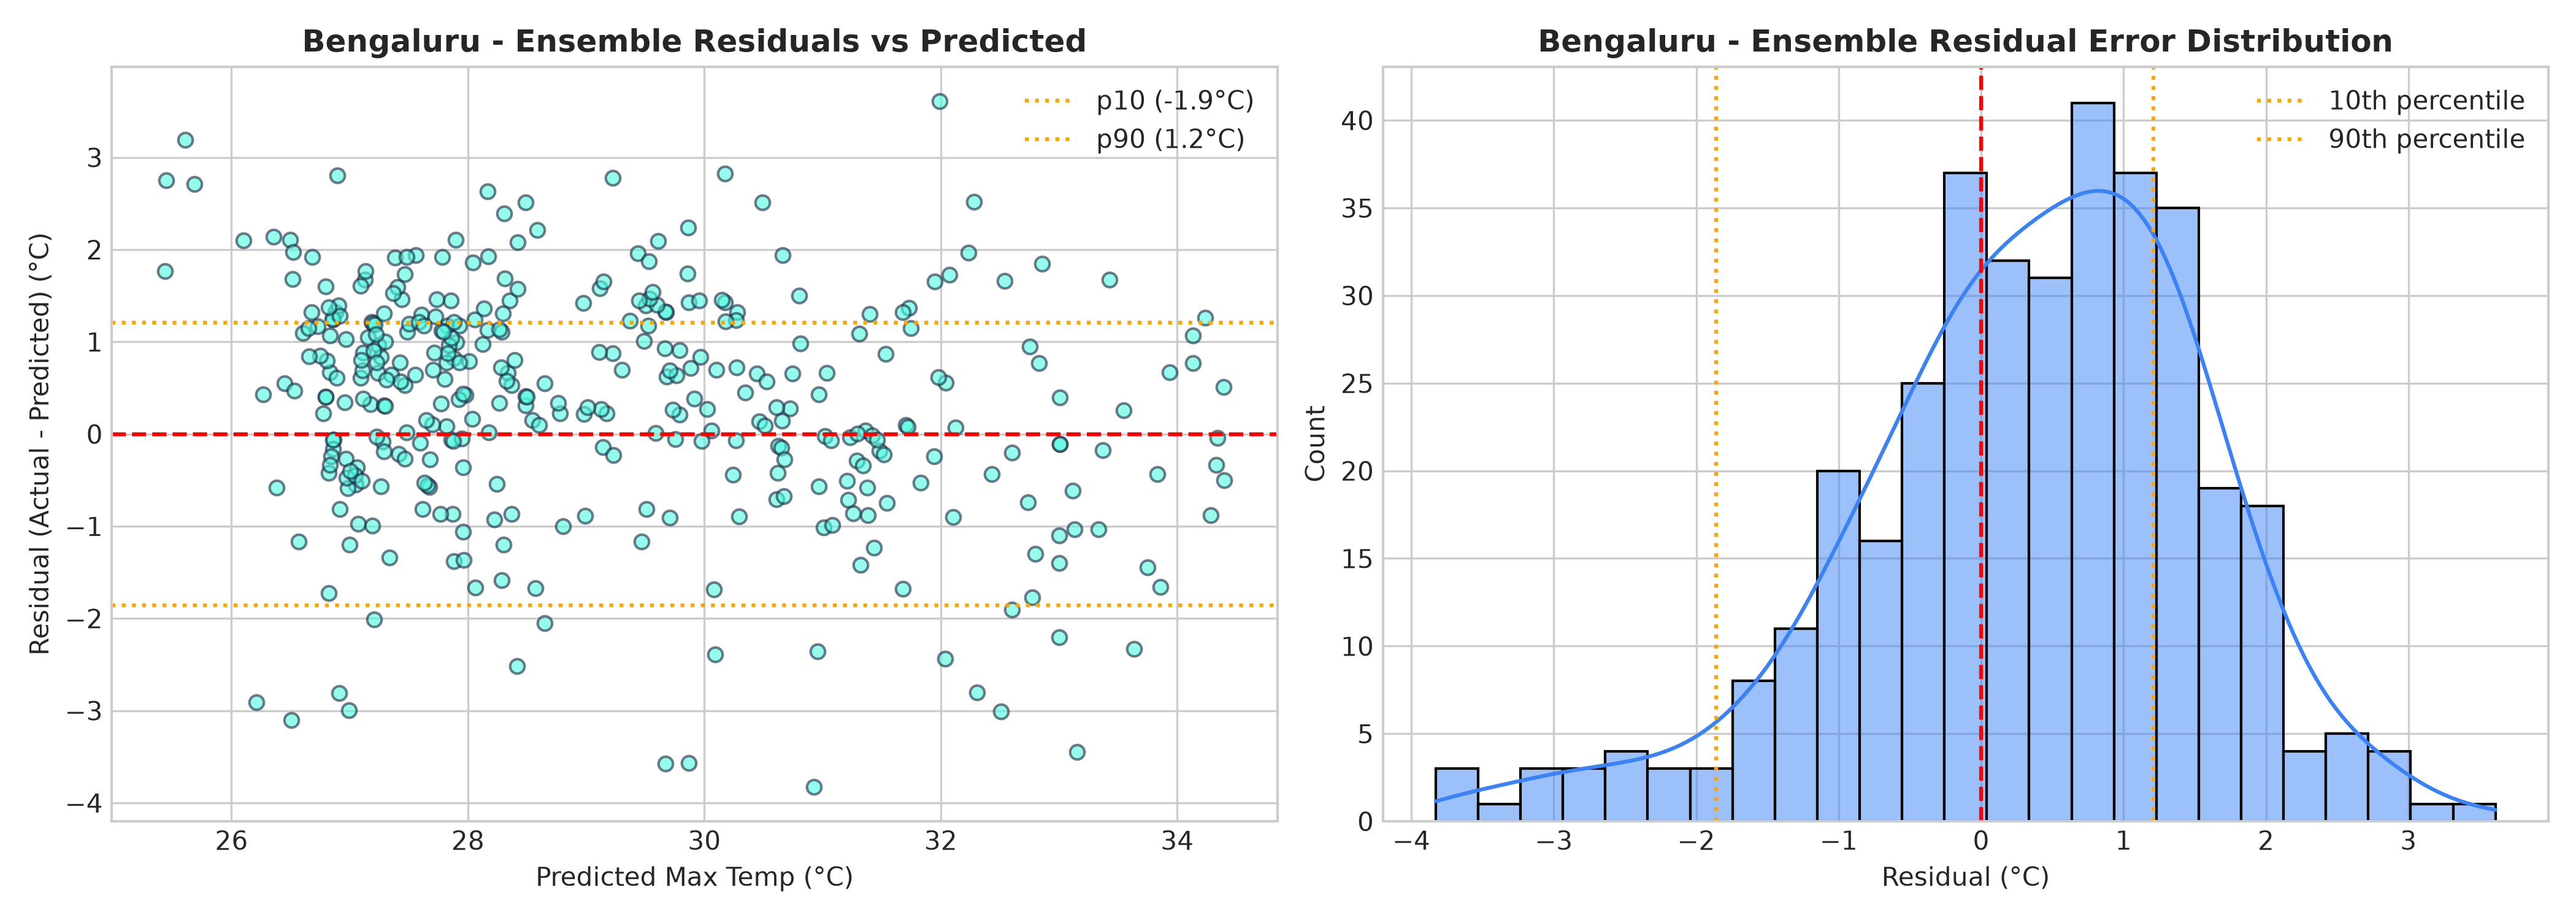

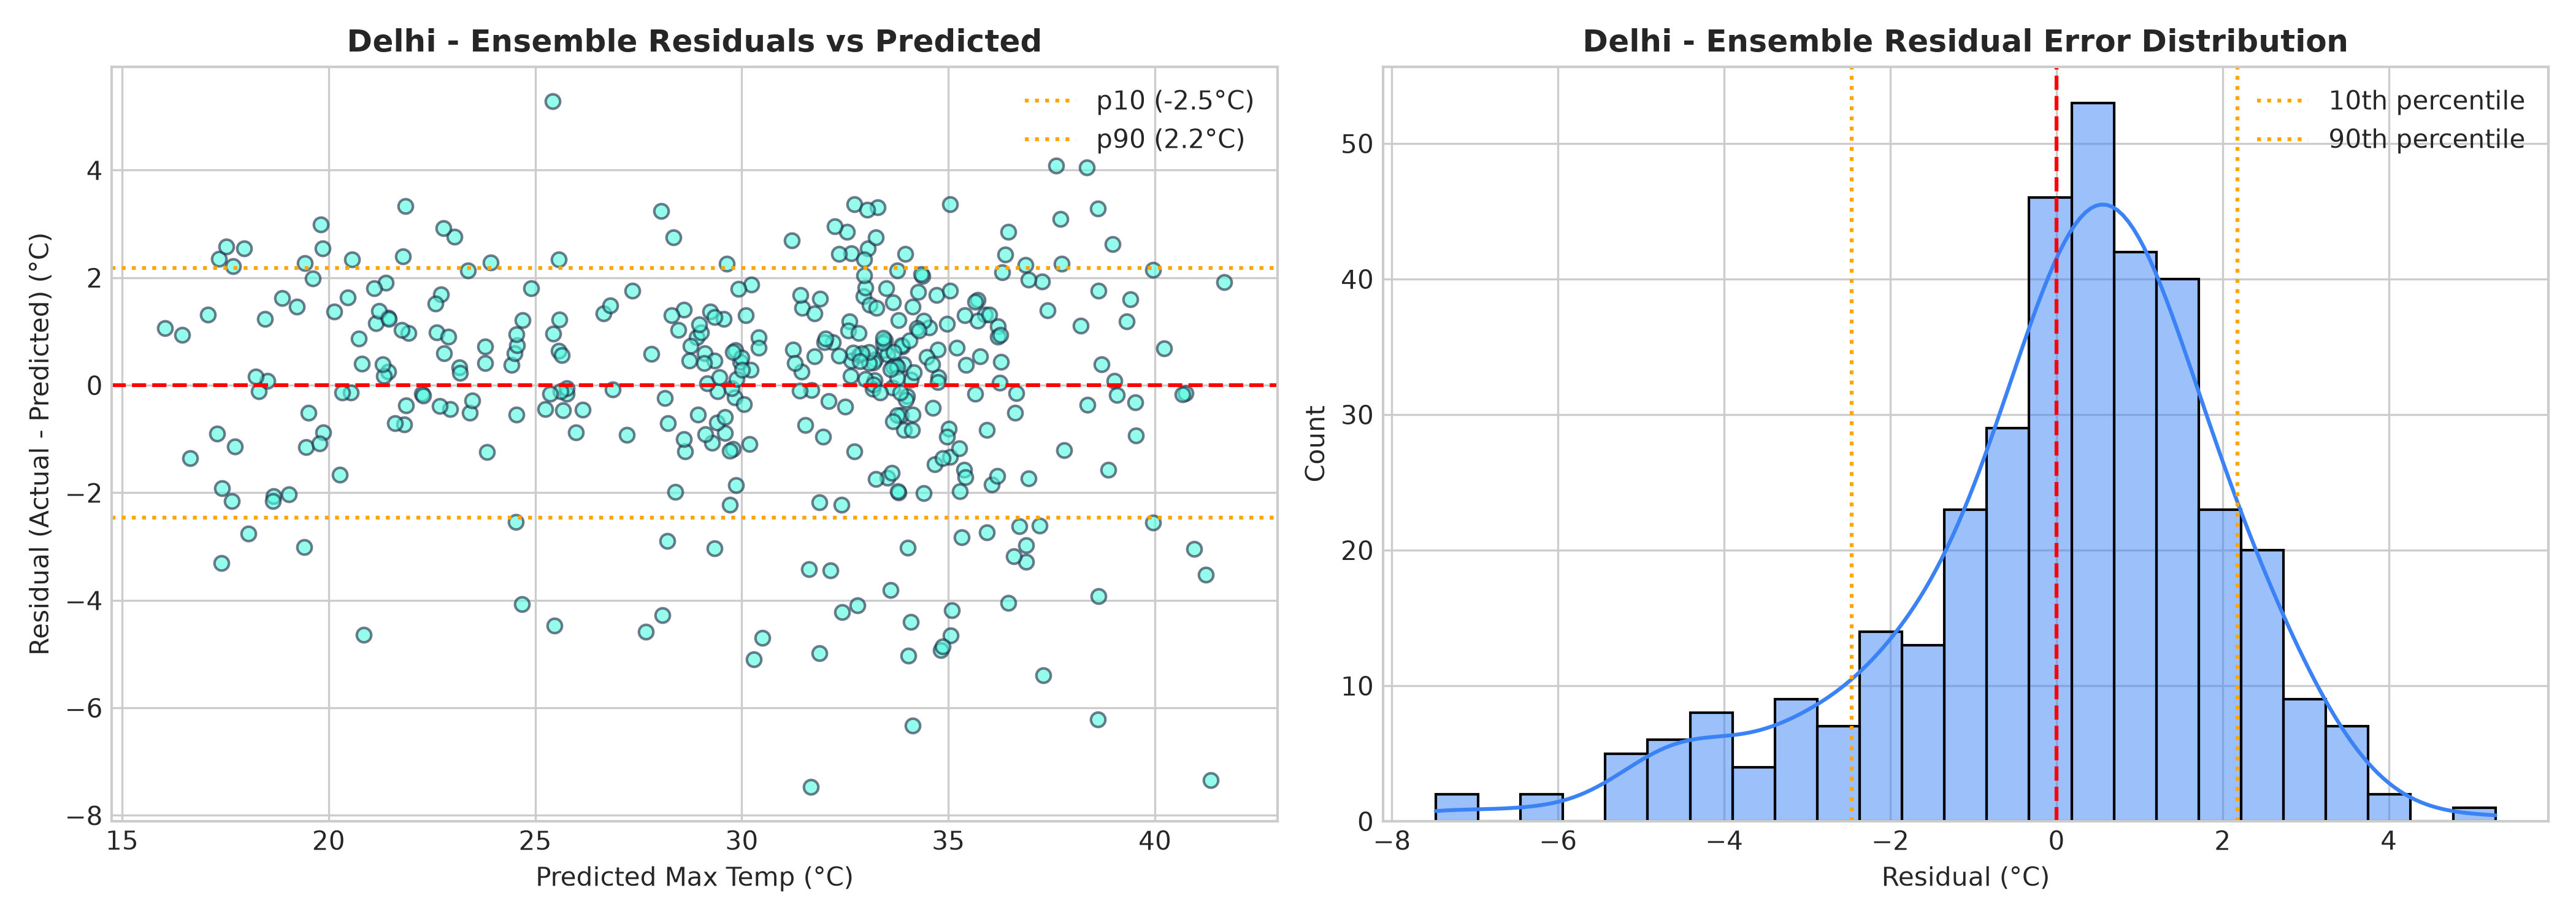

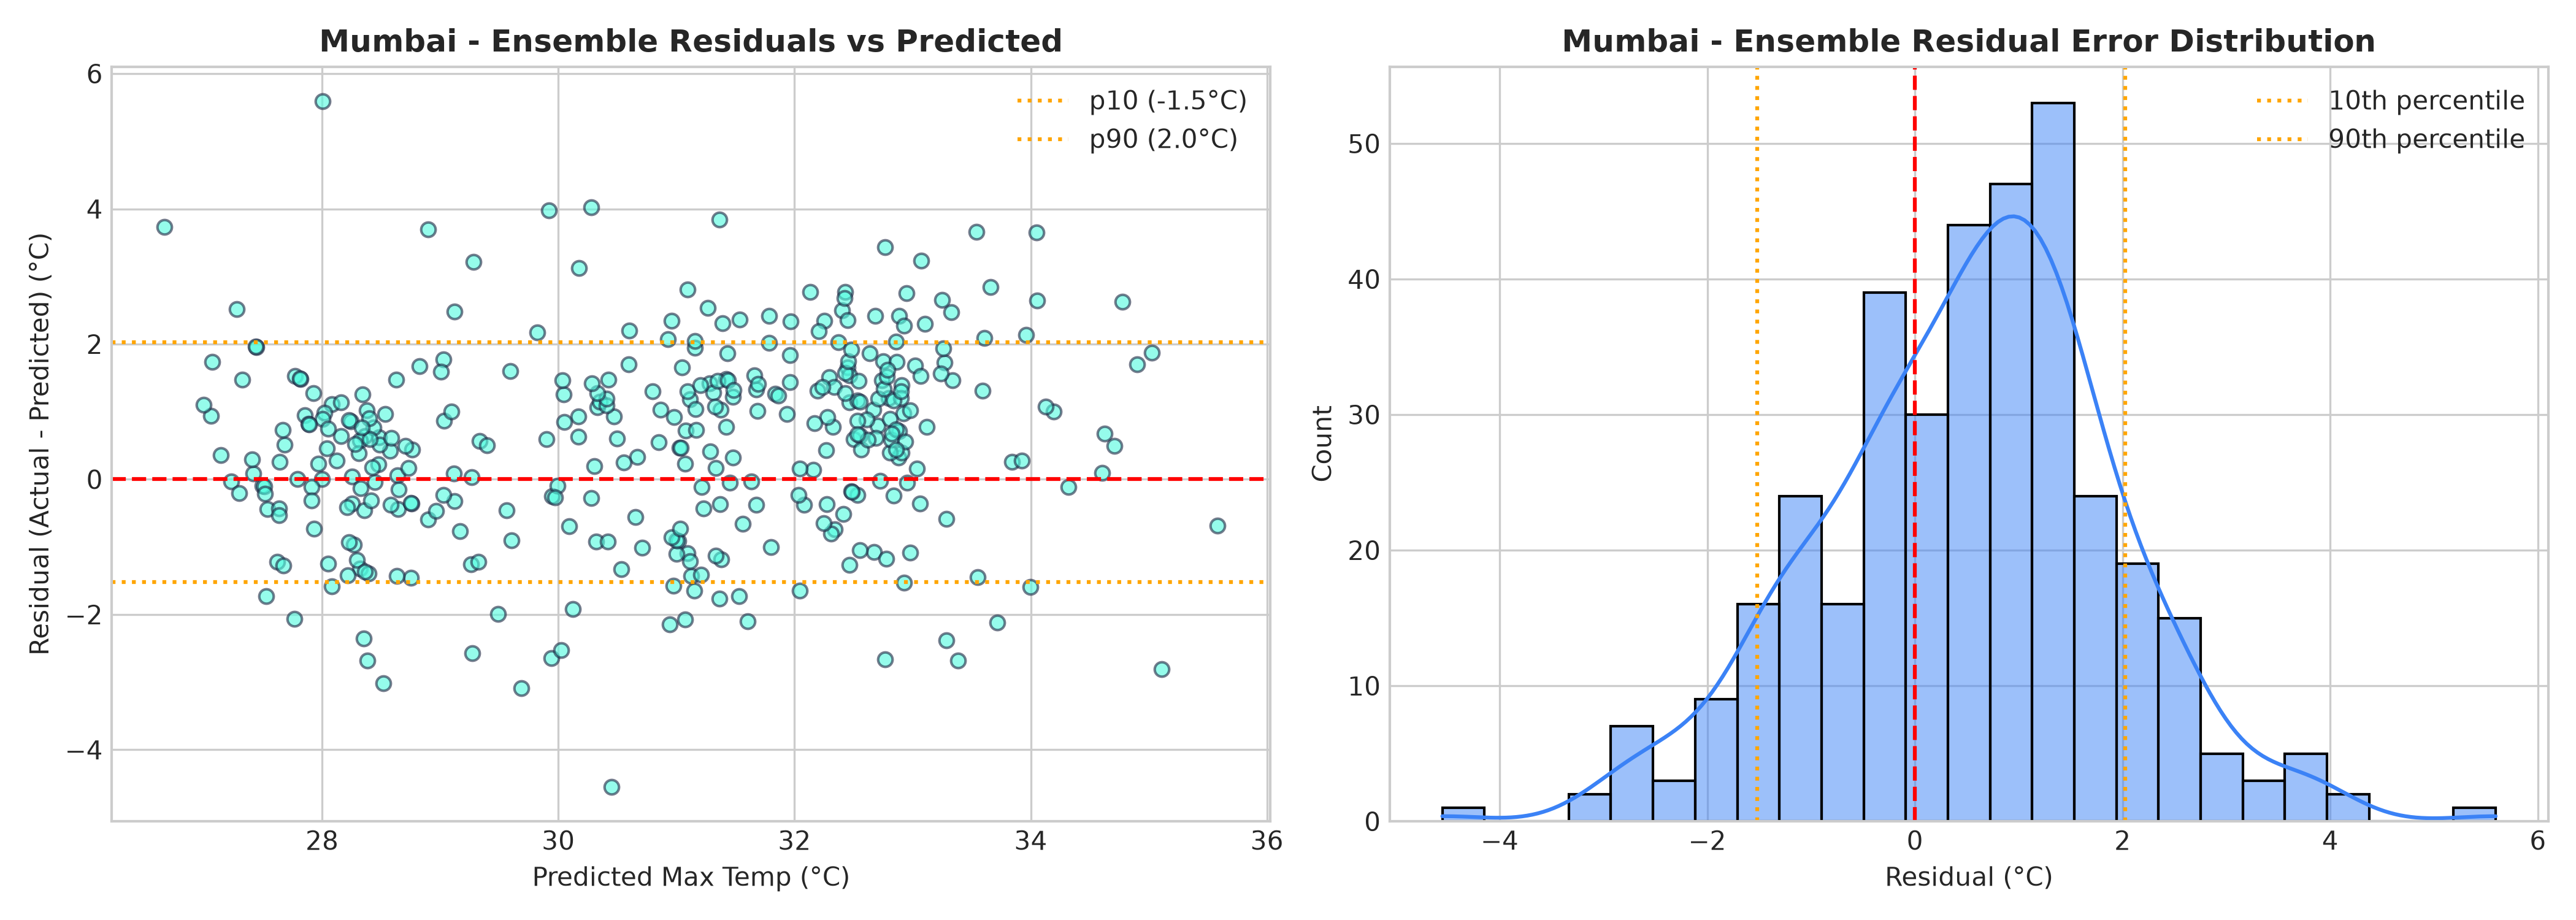

In [15]:
bias = pd.DataFrame({c: {"mean residual (actual - predicted)": r["served_interval"]["test_mean_residual"],
                         "validation p10": r["served_interval"]["p10"], "validation p90": r["served_interval"]["p90"]}
                     for c, r in reports.items()}).T
display(bias)
yearly = pd.DataFrame({c: df.groupby(df["date"].dt.year)["temperature_2m_max"].mean() for c, df in data.items()})
display(yearly.round(2).rename_axis("mean max temperature by year"))
for c in CITIES:
    display(FIG(f"residuals_{c}.png"))

A positive mean residual means the model under-predicted on average. In 2023 the ensemble under-predicted in
Bengaluru and Mumbai (by roughly 0.3–0.5 °C) but not in Delhi. The yearly means explain why: 2023 was about 0.9 °C
(Bengaluru) and 1.1 °C (Mumbai) warmer than 2019–2022, while Delhi's 2023 was not. A model trained on cooler years
tends to predict slightly too low in a warmer year. This shift is the main reason the interval coverage below falls
short of 80% in Bengaluru.

## 10. Prediction interval and its coverage

The API shows an 80% interval: prediction + [p10, p90], where p10 and p90 are the 10th and 90th percentiles of the
ensemble's out-of-fold errors in the training years. *Coverage* is the share of test days whose actual value fell
inside the interval actually shown (bounds rounded to 0.1 °C, inclusive). The approximate 95% range assumes independent
days; daily errors are correlated, so the true uncertainty is wider.

In [16]:
pd.DataFrame({c: {"coverage %": r["served_interval"]["test_coverage_pct"],
                  "approx 95% range": r["served_interval"]["test_coverage_approx_95ci"],
                  "test days": r["n_test"],
                  **{f"{s} %": v for s, v in r["served_interval"]["test_coverage_by_season"].items()},
                  "LightGBM quantile models % (not served)": r["quantile_models_reference"]["test_coverage_pct"]}
              for c, r in reports.items()}).T

,coverage %,approx 95% range,test days,Winter %,Pre-monsoon %,Monsoon %,Post-monsoon %,LightGBM quantile models % (not served)
bengaluru,72.3,"[67.7, 76.9]",365,82.2,69.6,70.5,65.6,66.8
delhi,77.5,"[73.3, 81.8]",365,77.8,63.0,81.1,91.8,75.3
mumbai,81.1,"[77.1, 85.1]",365,70.0,72.8,95.9,80.3,60.0


*Interpretation.* Delhi and Mumbai are close to the nominal 80%; Bengaluru is clearly below it (about 72%),
mainly because of the 2023 bias shown above. The interval assumes that future errors look like past errors; when the
climate of the test year shifts, coverage drops. The LightGBM quantile models that `src/train.py` also trains cover
fewer test days (60–75%), so they are not used by the API.

Possible improvements, which would have to be chosen on validation data rather than on 2023: excluding the first
cross-validation fold (trained on less than one year), retraining on more years, or updating the offsets with recent
errors.

## 11. Conclusions and limitations

* The pipeline is leak-free (features use only days up to *D*, climatology uses training years only, the split is
  chronological) and the reported metrics are reproducible from the saved artifacts.
* The ensemble beats climatology everywhere but only partly beats persistence on the 2023 test year.
* The 80% interval reaches roughly 78–81% coverage in Delhi and Mumbai but about 72% in Bengaluru.
* Limitations: only five years of data (four for training); a single grid point per city; reanalysis data for
  training but Open-Meteo forecast-model data for live inputs (a spot check of 6 days in October 2026 found
  differences of at most 0.3 °C); tree models cannot predict beyond the temperatures seen in training; one test year is
  a small, autocorrelated sample.

## 12. Team notes

*(To be written by the team in your own words: what you checked yourselves, what surprised you, and how you would
answer the viva questions in the blueprint.)*